    Name: Pride Mnisi
    StudentNo: 4503127

## Projectile motion

---

### Step size:

I used a step size of h=0.01 s and checked it with the equation we were given: |(x_h - x_(h/2))/x_(h/2)| ≤ 0.001. Here x_h is the horizontal range calculated with a 0.01 s step, and x_(h/2) is the range recalculated with a 0.005 s step. The code prints whether the difference meets 0.001 for each angle. This uses the given accuracy check instead of guessing a step size.

### Question 1

I'll use scipy.integrate.solve_ivp on the first-order position/velocity equations; it can find landing and simplifies integration through python.

30°: horizontal range 106.419 m; path distance 112.067 m
45°: horizontal range 122.883 m; path distance 141.044 m


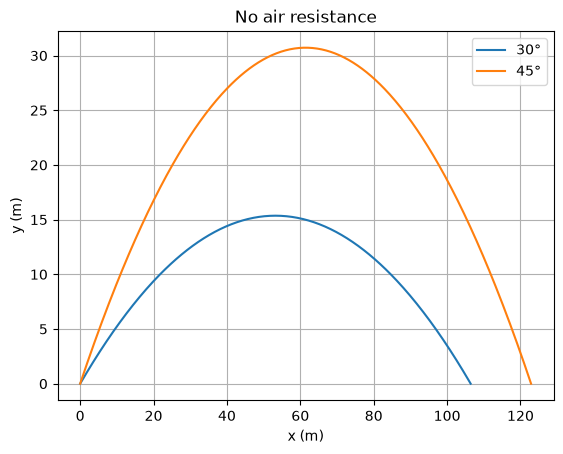

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#Data for the problem
v_i =34.72
g = 9.81
dt = 0.01

#Functions for the ODE and the event
def rhs(t,s): 
   return s[2],s[3],0.,-g

#Define the event function to stop integration when the projectile hits the ground
def ground(t,s): 
   return s[1]


# Initializing the attributes
ground.terminal=True; ground.direction=-1

fig,ax=plt.subplots()

# Loop over the angles of projection
for a in (30,45):

    th=np.deg2rad(a); s0=(0,0,v_i*np.cos(th),v_i*np.sin(th))
    
    sol=solve_ivp(rhs,(0,10),s0,events=ground,dense_output=True,rtol=1e-9,atol=1e-11,max_step=dt)
    tf=sol.t_events[0][0]; t=np.append(np.arange(0,tf,dt),tf); x,y,vx,vy=sol.sol(t)
    d=x[-1]-x[0]; p=np.trapezoid(np.hypot(vx,vy),t); ax.plot(x,y,label=f"{a}°")
    print(f"{a}°: horizontal range {d:.3f} m; path distance {p:.3f} m")

ax.set(xlabel="x (m)",ylabel="y (m)",title="No air resistance"); ax.grid(); ax.legend(); plt.show()

### Question 2:

I'll use solve_ivp with the same descending-ground event.
#### Data
- mass=0.029 kg
- g=9.81
- v_i = 34.72
- Cd=0.1
- air density 1.225 kg/m^3
- area 0.01 m^2 
- a_drag = -(Cd*rho*A/(2*m))*|v|*v 
- step 0.01s 

30°: horizontal range 46.217 m; path distance 50.905 m
45°: horizontal range 46.508 m; path distance 59.562 m


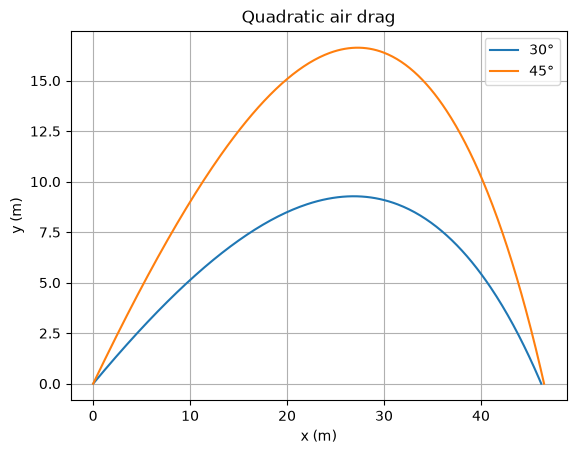

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#data:
v_i=34.72
g=9.81
dt=0.01
m=0.029
Cd=0.1
rho=1.225
A=0.01
k=Cd*rho*A/(2*m)

# Functions for the ODE and the event
def rhs(t,s):
    x,y,vx,vy=s; q=np.hypot(vx,vy); return vx,vy,-k*q*vx,-k*q*vy-g

def ground(t,s): return s[1]

ground.terminal=True; ground.direction=-1

fig,ax=plt.subplots()

for a in (30,45):
    th=np.deg2rad(a); s0=(0,0,v_i*np.cos(th),v_i*np.sin(th))

    sol=solve_ivp(rhs,(0,10),s0,events=ground,dense_output=True,rtol=1e-9,atol=1e-11,max_step=dt)
    tf=sol.t_events[0][0]; t=np.append(np.arange(0,tf,dt),tf); x,y,vx,vy=sol.sol(t)

    
    d=x[-1]-x[0]; p=np.trapezoid(np.hypot(vx,vy),t); ax.plot(x,y,label=f"{a}°")
    print(f"{a}°: horizontal range {d:.3f} m; path distance {p:.3f} m")

ax.set(xlabel="x (m)",ylabel="y (m)",title="Quadratic air drag"); ax.grid(); ax.legend(); plt.show()

### Bonus Question 
Wind velocities are (-10,0) m/s and (8,3) m/s. Position advances with ground velocity, but drag uses relative air velocity v_ball-v_wind and acceleration -(Cd*rho*A/(2*m))*|v_rel|*v_rel. 
Wind and Question 2 parameters are constant. Panels compare both launch angles in each wind.

Wind (-10,0), 30°: horizontal range 28.038 m; path distance 34.901 m
Wind (-10,0), 45°: horizontal range 22.069 m; path distance 41.242 m
Wind (8,3), 30°: horizontal range 66.754 m; path distance 71.469 m
Wind (8,3), 45°: horizontal range 72.526 m; path distance 85.268 m


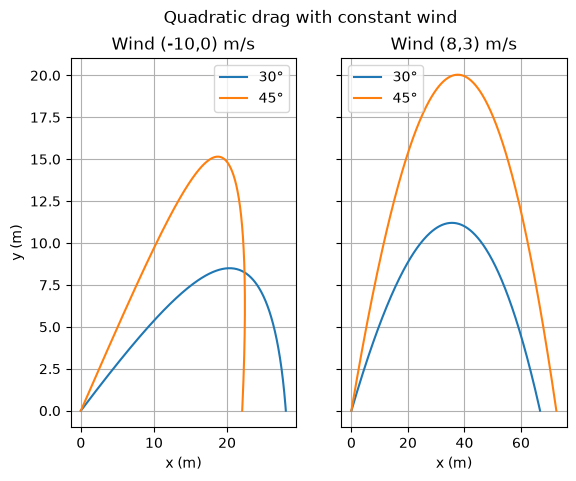

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
#data:
v_i=34.72
g=9.81
dt=0.01
m=0.029
Cd=0.1
rho=1.225
A=0.01
k=Cd*rho*A/(2*m)
# Functions for the ODE and the event
def make_rhs(wx,wy):
    def rhs(t,s):
        x,y,vx,vy=s; ux,uy=vx-wx,vy-wy; q=np.hypot(ux,uy)
        return vx,vy,-k*q*ux,-k*q*uy-g
    return rhs

def ground(t,s): return s[1]

# the event function to stop integration when the projectile hits the
ground.terminal=True; ground.direction=-1



# Set up the figure and axes for plotting
fig,axs=plt.subplots(1,2,sharey=True)



# Loop over the wind conditions and angles of projection
for ax,(wx,wy) in zip(axs,[(-10,0),(8,3)]):
    for a in (30,45):
        th=np.deg2rad(a); s0=(0,0,v_i*np.cos(th),v_i*np.sin(th))
        
        sol=solve_ivp(make_rhs(wx,wy),(0,10),s0,events=ground,dense_output=True,rtol=1e-9,atol=1e-11,max_step=dt)
        
        
        tf=sol.t_events[0][0]; t=np.append(np.arange(0,tf,dt),tf); x,y,vx,vy=sol.sol(t)
        
        d=x[-1]-x[0]; p=np.trapezoid(np.hypot(vx,vy),t); ax.plot(x,y,label=f"{a}°")
        
        print(f"Wind ({wx},{wy}), {a}°: horizontal range {d:.3f} m; path distance {p:.3f} m")
    
    
    # set the title, labels, grid, and legend for the current subplot
    ax.set(title=f"Wind ({wx},{wy}) m/s",xlabel="x (m)"); ax.grid(); ax.legend()

# plotting the results
axs[0].set_ylabel("y (m)"); fig.suptitle("Quadratic drag with constant wind"); plt.show()